# Part A – Understanding the Dataset

## 1.1 Loading the Dataset

The first step is to import the required Python libraries and load the customer churn dataset.

We use:
- Pandas for data loading, manipulation and summary statistics.
- Numpy for numerical operations.
- Matplotlib and Seaborn for data visualization.

At this stage, we only load and inspect the original dataset. No data cleaning. No cleaning or transformations are performed.

In [1]:
# here, we upload the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset automatically from GitHub
csv_url = "https://raw.githubusercontent.com/2026em1100040-pixel/Riddhi_bhatt_FE_assignment1/refs/heads/main/Graded_Assignment_2_Dataset%20(1).csv"

df = pd.read_csv(csv_url)

sns.set_theme(style="whitegrid")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())
df.info()



Dataset loaded successfully!
Dataset shape: (5000, 32)


,Customer_ID,Age,Gender,Region,Marital_Status,Tenure_Months,Tenure_Years,Contract_Type,Payment_Method,Paperless_Billing,...,Unresolved_Tickets_Count,Avg_Resolution_Time_Hours,Customer_Satisfaction_Score,NPS_Score,System_Stability_Score,Service_Disruption_Events,Engagement_Index,Charge_Band,Tenure_Segment,Churn
0,CUST100001,46,Female,South,Single,45,3.8,One-Year,Credit Card,Yes,...,1,39.4,2.0,1,4,1,NaN,Moderate,Loyal,0
1,CUST100002,39,Female,North,Single,6,0.5,Month-to-Month,Electronic Check,Yes,...,0,11.7,2.0,9,4,2,43.77,Premium,New,1
2,CUST100003,48,Female,West,Married,21,1.8,Month-to-Month,Mailed Check,Yes,...,0,3.4,3.0,2,2,1,25.17,Moderate,Established,0
3,CUST100004,59,Female,South,Married,46,3.8,Month-to-Month,Credit Card,Yes,...,0,32.7,3.0,4,3,1,49.03,Moderate,Loyal,0
4,CUST100005,38,Female,South,Single,12,1.0,Month-to-Month,Mailed Check,Yes,...,0,5.7,5.0,5,5,1,58.83,Moderate,New,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer_ID                  5000 non-null   object 
 1   Age                          5000 non-null   int64  
 2   Gender                       5000 non-null   object 
 3   Region                       5000 non-null   object 
 4   Marital_Status               4903 non-null   object 
 5   Tenure_Months                5000 non-null   int64  
 6   Tenure_Years                 5000 non-null   float64
 7   Contract_Type                5000 non-null   object 
 8   Payment_Method               5000 non-null   object 
 9   Paperless_Billing            5000 non-null   object 
 10  Internet_Service_Type        4252 non-null   object 
 11  Device_Protection            5000 non-null   object 
 12  Tech_Support_Tier            2536 non-null   object 
 13  Num_Streaming_Serv

### 1.2 Summary Statistics
Summary Statistics provide an overview of the numerical characteristics of the dataset.

We will examine measures such as:
- Mean: Average value of a feature.
- Standard deviation: Measures the spread of values around the mean.
- Minimum and maximum: identify the smallest and largest observations.
- Quartiles: Describe how the data is distributed across four equal parts.

These statistics help us understand the scale, variability, and distribution of numerical features and identify variables that may require further investigation.


,count,mean,std,min,25%,50%,75%,max
Age,5000.0,40.707600,11.600061,18.00,33.0000,41.000,48.0000,75.00
Tenure_Months,5000.0,21.836600,19.728551,1.00,6.0000,16.000,32.0000,72.00
Tenure_Years,5000.0,1.820440,1.643710,0.10,0.5000,1.300,2.7000,6.00
Num_Streaming_Services,5000.0,1.645600,1.225847,0.00,1.0000,1.000,2.0000,4.00
Avg_Daily_Usage_Minutes,5000.0,126.408240,88.455487,4.00,71.0000,109.300,161.0500,969.70
Monthly_Logins,5000.0,18.057000,4.263495,5.00,15.0000,18.000,21.0000,35.00
Inactivity_Days,5000.0,12.258400,11.398106,1.00,4.0000,9.000,17.0000,60.00
Monthly_Charges,5000.0,84.540092,25.155938,20.00,66.5750,83.505,101.9100,165.86
Estimated_Annual_Charges,5000.0,1014.597372,302.120185,231.30,799.0325,1003.465,1224.3325,1992.80
Total_Charges,4836.0,1817.807095,1803.594314,18.96,466.5550,1246.440,2563.0075,10809.01


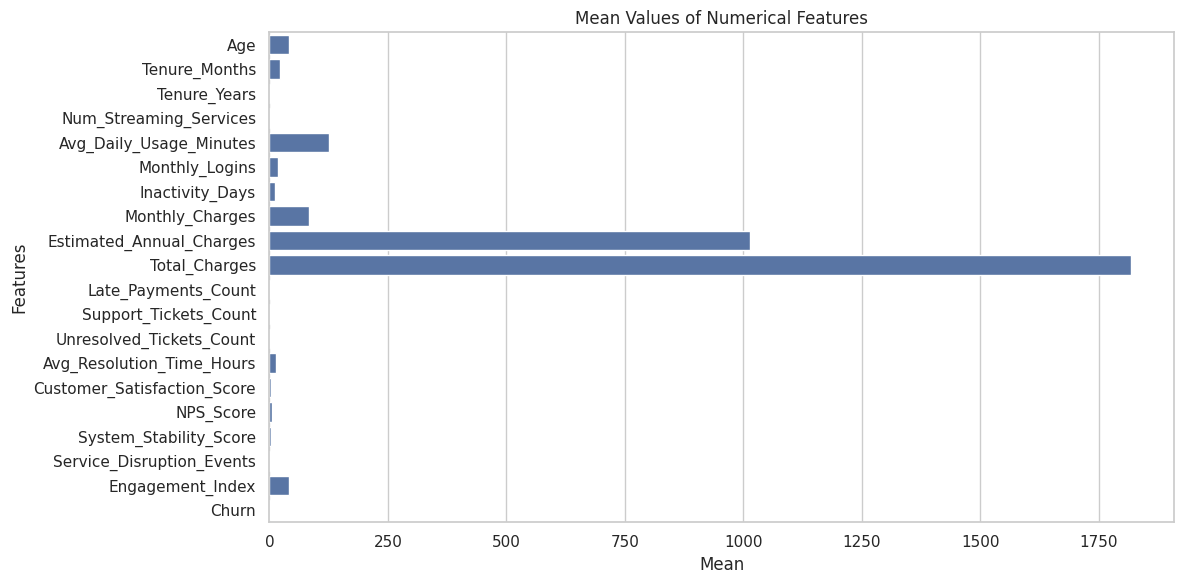

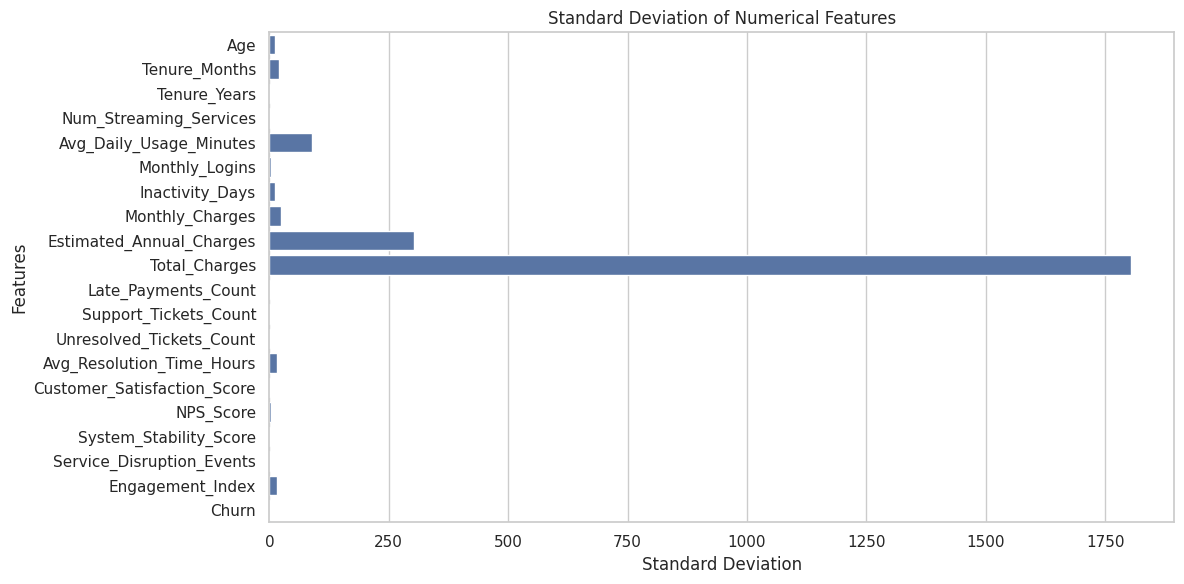

In [2]:
# summary statistics
numerical_summary = df.describe().T
display(numerical_summary)



# Visualize mean values

plt.figure(figsize=(12, 6))

sns.barplot(
    x=df.select_dtypes(include=np.number).mean().values,
    y=df.select_dtypes(include=np.number).columns
)

plt.title("Mean Values of Numerical Features")
plt.xlabel("Mean")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


# Visualize standard deviation

plt.figure(figsize=(12, 6))

sns.barplot(
    x=df.select_dtypes(include=np.number).std().values,
    y=df.select_dtypes(include=np.number).columns
)

plt.title("Standard Deviation of Numerical Features")
plt.xlabel("Standard Deviation")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


### 1.3 Missing Value Analysis

Missing values occur when observations are not available for certain features.

Identifying missing values is an important part of data quality assessment because incomplete observations can affect statistical analysis and subsequent preprocessing operations.

We calculate both the number and percentage of missing values in each feature. A visualization is also used to identify columns with a relatively high proportion of missing observations.


,Missing Values,Missing Percentage
Tech_Support_Tier,2464,49.28
Internet_Service_Type,748,14.96
Avg_Resolution_Time_Hours,325,6.50
Customer_Satisfaction_Score,230,4.60
Engagement_Index,221,4.42
Total_Charges,164,3.28
Marital_Status,97,1.94


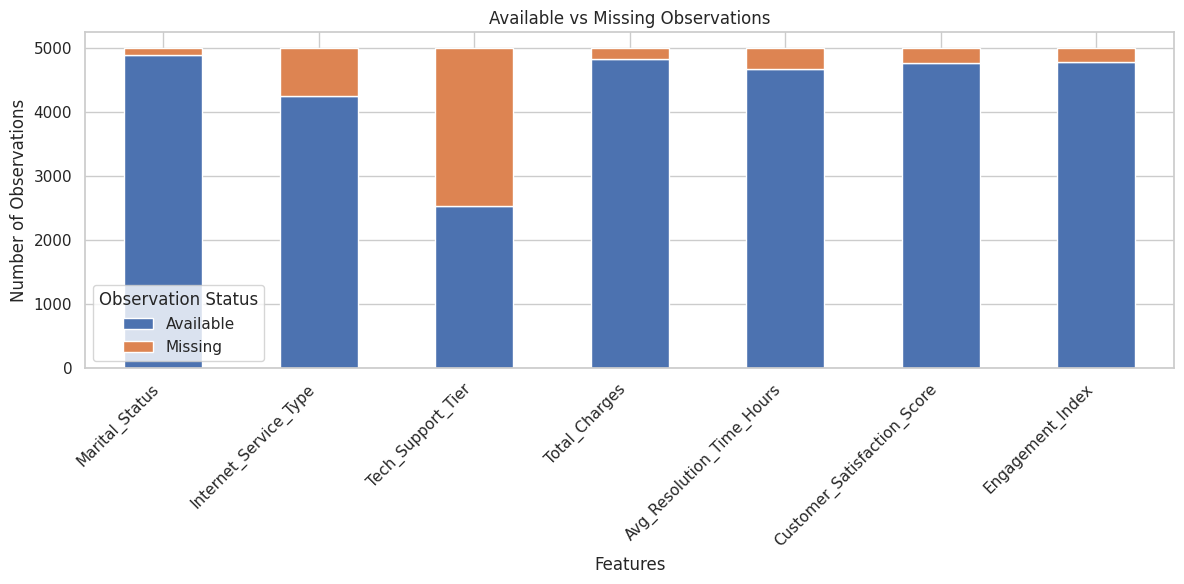

In [3]:

# Calculate missing values and their percentages

missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

# Display only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)


# Compare available and missing observations

missing_visual = pd.DataFrame({
    "Available": df.notnull().sum(),
    "Missing": df.isnull().sum()
})

missing_visual = missing_visual[
    missing_visual["Missing"] > 0
]

missing_visual.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Available vs Missing Observations")
plt.xlabel("Features")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Observation Status")
plt.tight_layout()
plt.show()


### 1.4 Numerical Feature Distribution Analysis

Numerical feature distribution analysis helps us understand how values are spread across different variables.

Histograms are used to visualize the frequency distribution of numerical features.

The shape of a distribution can provide useful insights:

- **Symmetrical distribution:** Values are distributed relatively evenly around the centre.
- **Positive skewness:** Most observations are concentrated on the left, with a longer tail towards higher values.
- **Negative skewness:** Most observations are concentrated on the right, with a longer tail towards lower values.

Identifying skewed features is important because certain transformations, such as logarithmic or power transformations, may improve the distribution of highly skewed variables.

At this stage, we will only analyse the original distributions. No transformations will be applied.

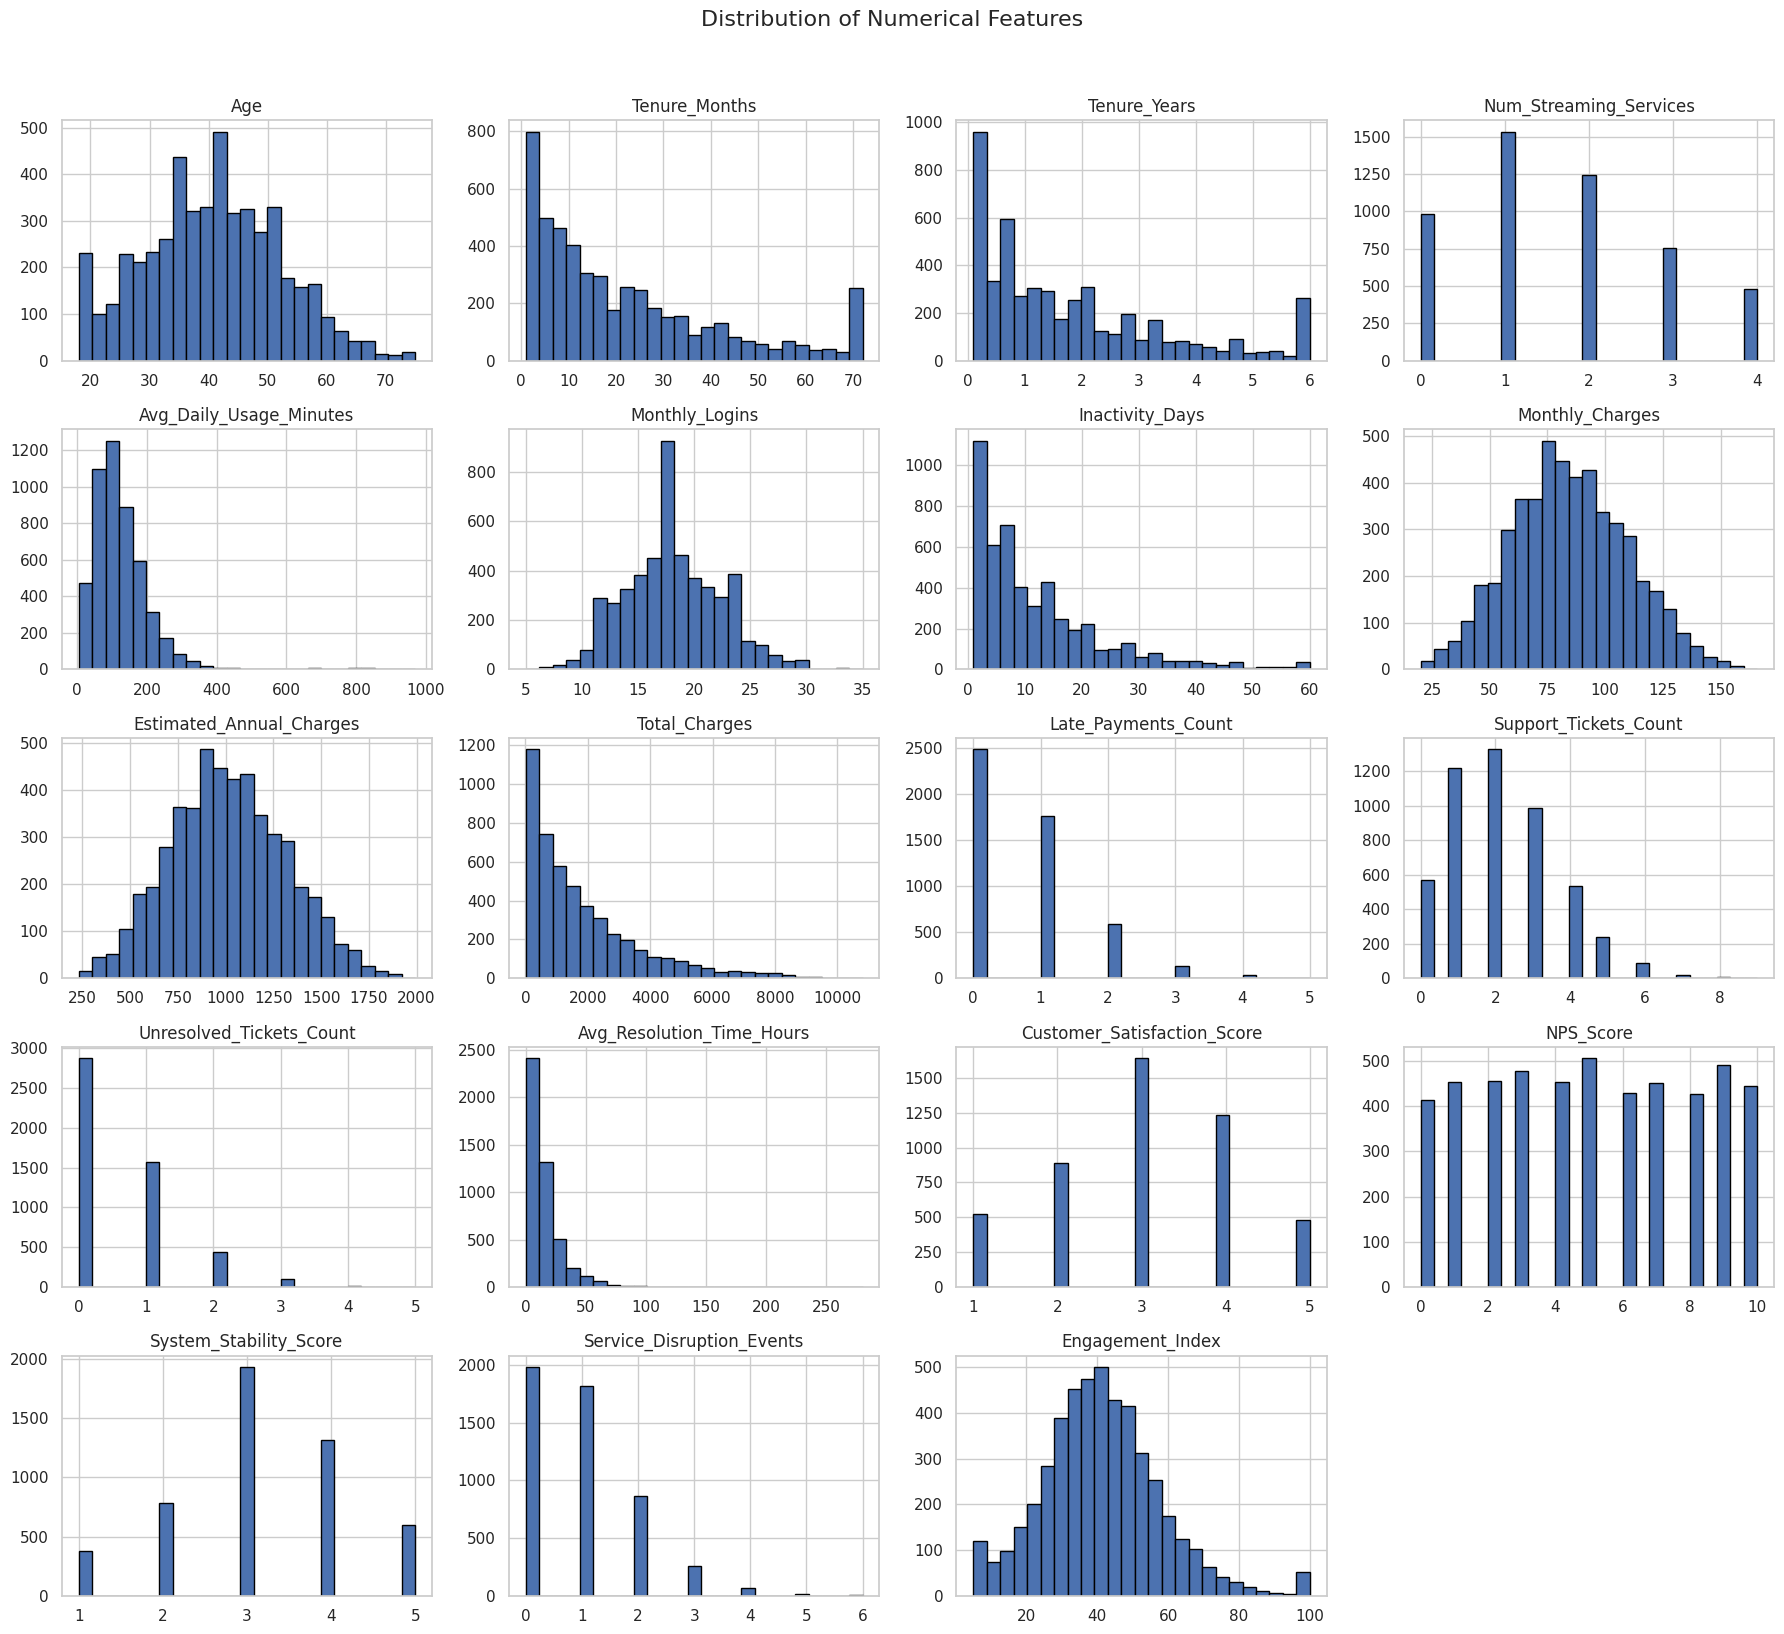

In [4]:

# here we have done particular analysis on each feature excluding the target variable
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

numeric_columns = [
    col for col in numeric_columns
    if col != "Churn"
]

# Plot histograms
df[numeric_columns].hist(
    figsize=(18, 16),
    bins=25,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


### 1.5 Skewness Analysis

Skewness measures the asymmetry of a numerical distribution.

A skewness value close to zero generally indicates a relatively symmetrical distribution. Positive values indicate right-skewness, while negative values indicate left-skewness.

We calculate skewness for each numerical feature to identify variables that may require further investigation during preprocessing.

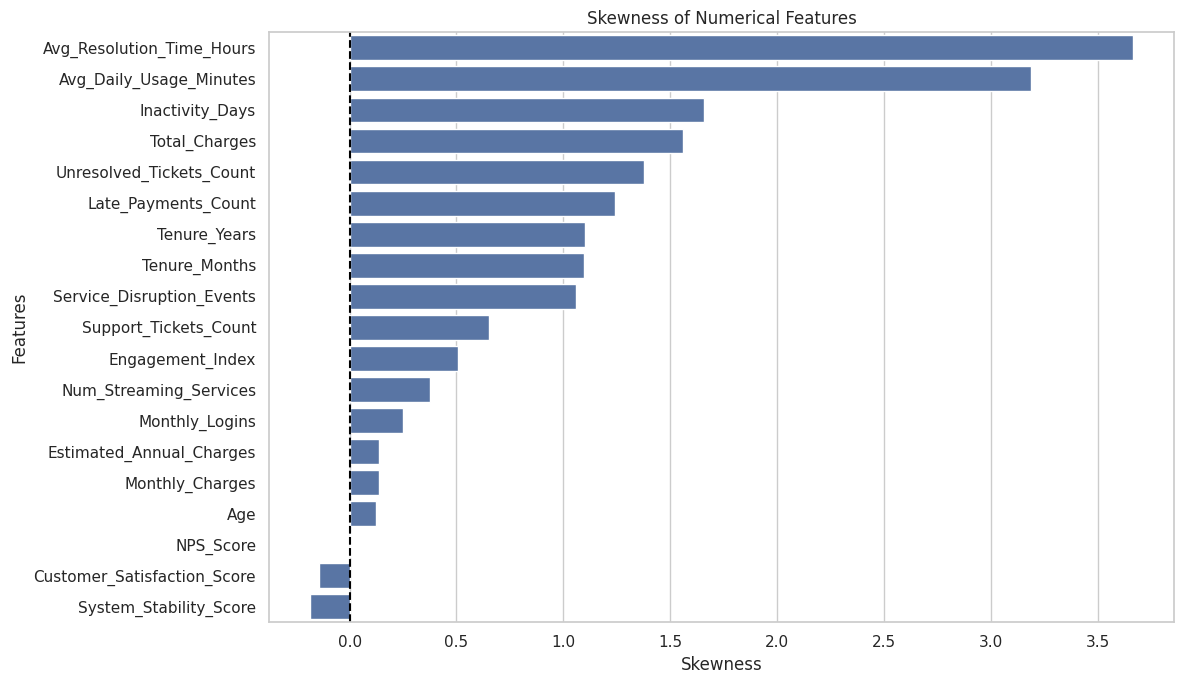

In [5]:

# Calculate skewness for numerical features

skewness_values = df[numeric_columns].skew().sort_values(
    ascending=False
)

skewness_summary = pd.DataFrame({
    "Skewness": skewness_values
})

plt.figure(figsize=(12, 7))

sns.barplot(
    x=skewness_summary["Skewness"],
    y=skewness_summary.index
)

plt.axvline(
    x=0,
    color="black",
    linestyle="--"
)

plt.title("Skewness of Numerical Features")
plt.xlabel("Skewness")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

# if the skewness value is close to 0, it is approximately symmetrical
# if the skewness value is greater than 0, it is positively skewed
# if the skewness value is less than 0, it is negatively skewed
# if the skewness value is above +1 or below -1, it is strongly skewed

### 1.6 Outlier Detection and Analysis

Outliers are observations that differ considerably from the majority of values in a feature.

They may occur due to genuine variations in customer behaviour, unusual circumstances, or data-entry errors.

To identify potential outliers, we use:

**1. Boxplots:** These visually represent the median, quartiles, spread, and potential outliers in numerical features.

**2. Interquartile Range (IQR) method:** The IQR measures the spread of the middle 50% of observations.

\[
IQR = Q3 - Q1
\]

The lower and upper boundaries are calculated as:

\[
Lower = Q1 - 1.5 \times IQR
\]

\[
Upper = Q3 + 1.5 \times IQR
\]

Observations outside these boundaries are flagged as potential outliers.

These observations will not be removed automatically. Their relevance will be evaluated before deciding whether any treatment is necessary.

,Lower Limit,Upper Limit,Potential Outliers,Outlier Percentage
Num_Streaming_Services,-0.50000,3.50000,482,9.64
System_Stability_Score,1.50000,5.50000,376,7.52
Service_Disruption_Events,-1.50000,2.50000,341,6.82
Avg_Resolution_Time_Hours,-15.10000,40.10000,297,5.94
Inactivity_Days,-15.50000,36.50000,244,4.88
Total_Charges,-2678.12375,5707.68625,231,4.62
Tenure_Months,-33.00000,71.00000,229,4.58
Late_Payments_Count,-1.50000,2.50000,169,3.38
Avg_Daily_Usage_Minutes,-64.07500,296.12500,156,3.12
Unresolved_Tickets_Count,-1.50000,2.50000,108,2.16


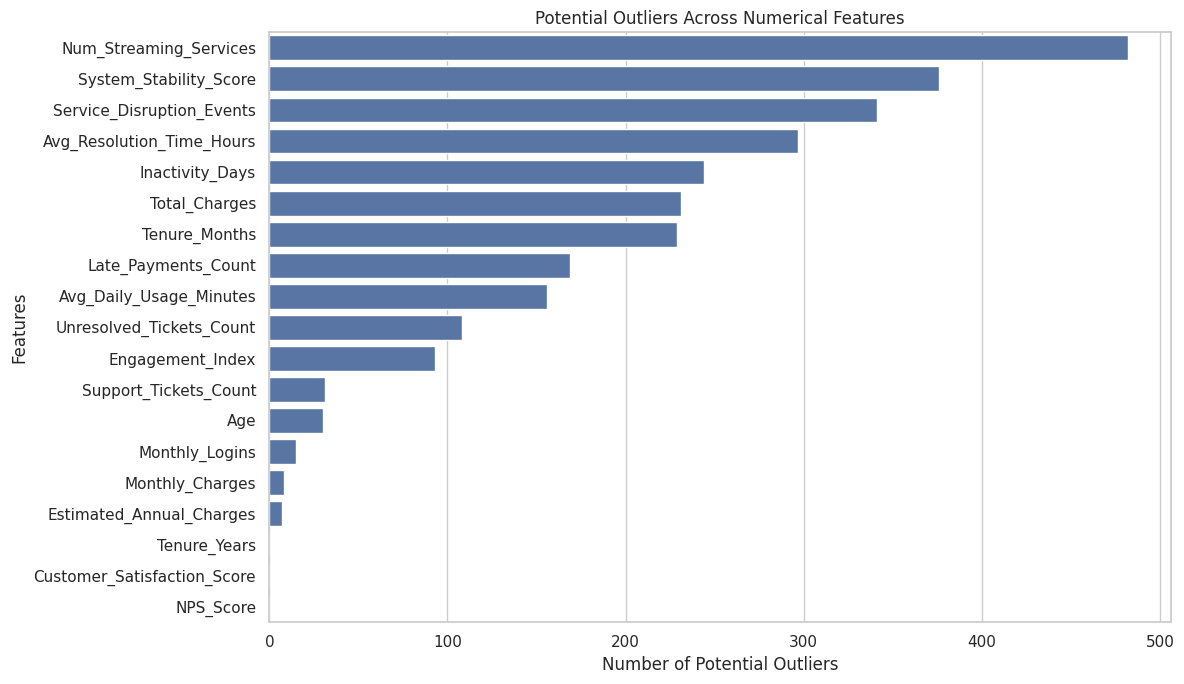

In [6]:

# Step 1: Calculate Q1, Q3 and IQR

Q1 = df[numeric_columns].quantile(0.25)
Q3 = df[numeric_columns].quantile(0.75)

IQR = Q3 - Q1

# Step 2: Calculate lower and upper limits

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Step 3: Count potential outliers

outlier_counts = (
    (df[numeric_columns] < lower_limit) |
    (df[numeric_columns] > upper_limit)
).sum()

# Step 4: Create outlier summary

outlier_summary = pd.DataFrame({
    "Lower Limit": lower_limit,
    "Upper Limit": upper_limit,
    "Potential Outliers": outlier_counts,
    "Outlier Percentage": (
        outlier_counts / len(df) * 100
    ).round(2)
})

# Step 5: Display summary

display(
    outlier_summary.sort_values(
        by="Potential Outliers",
        ascending=False
    )
)

# Step 6: Visualize potential outliers

outlier_plot = (
    outlier_summary
    .sort_values(
        by="Potential Outliers",
        ascending=False
    )
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=outlier_plot,
    x="Potential Outliers",
    y="index"
)

plt.title("Potential Outliers Across Numerical Features")
plt.xlabel("Number of Potential Outliers")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


### 1.7 Categorical Feature Analysis

Categorical features represent customer characteristics and service-related classifications.

Analysing their frequency distributions helps us understand:
- The number of observations in each category.
- Whether certain categories are more common than others.
- Whether some categories have very few observations.
- Whether missing values are present.

Bar charts and frequency tables will be used to visualize these distributions.

This analysis will help us decide which encoding techniques are appropriate during the preprocessing stage.

No encoding or modifications will be performed at this stage.


Distribution of Gender:


,Count
Gender,
Female,2435
Male,2412
Non-Binary,153



Distribution of Region:


,Count
Region,
North,1284
West,1246
South,992
East,970
Central,508



Distribution of Marital_Status:


,Count
Marital_Status,
Married,2517
Single,1633
Divorced,753
NaN,97


... (6 outputs left out)


Distribution of Device_Protection:


,Count
Device_Protection,
No,2475
Yes,1779
No Internet,746



Distribution of Tech_Support_Tier:


,Count
Tech_Support_Tier,
NaN,2464
Standard,1784
Premium,752


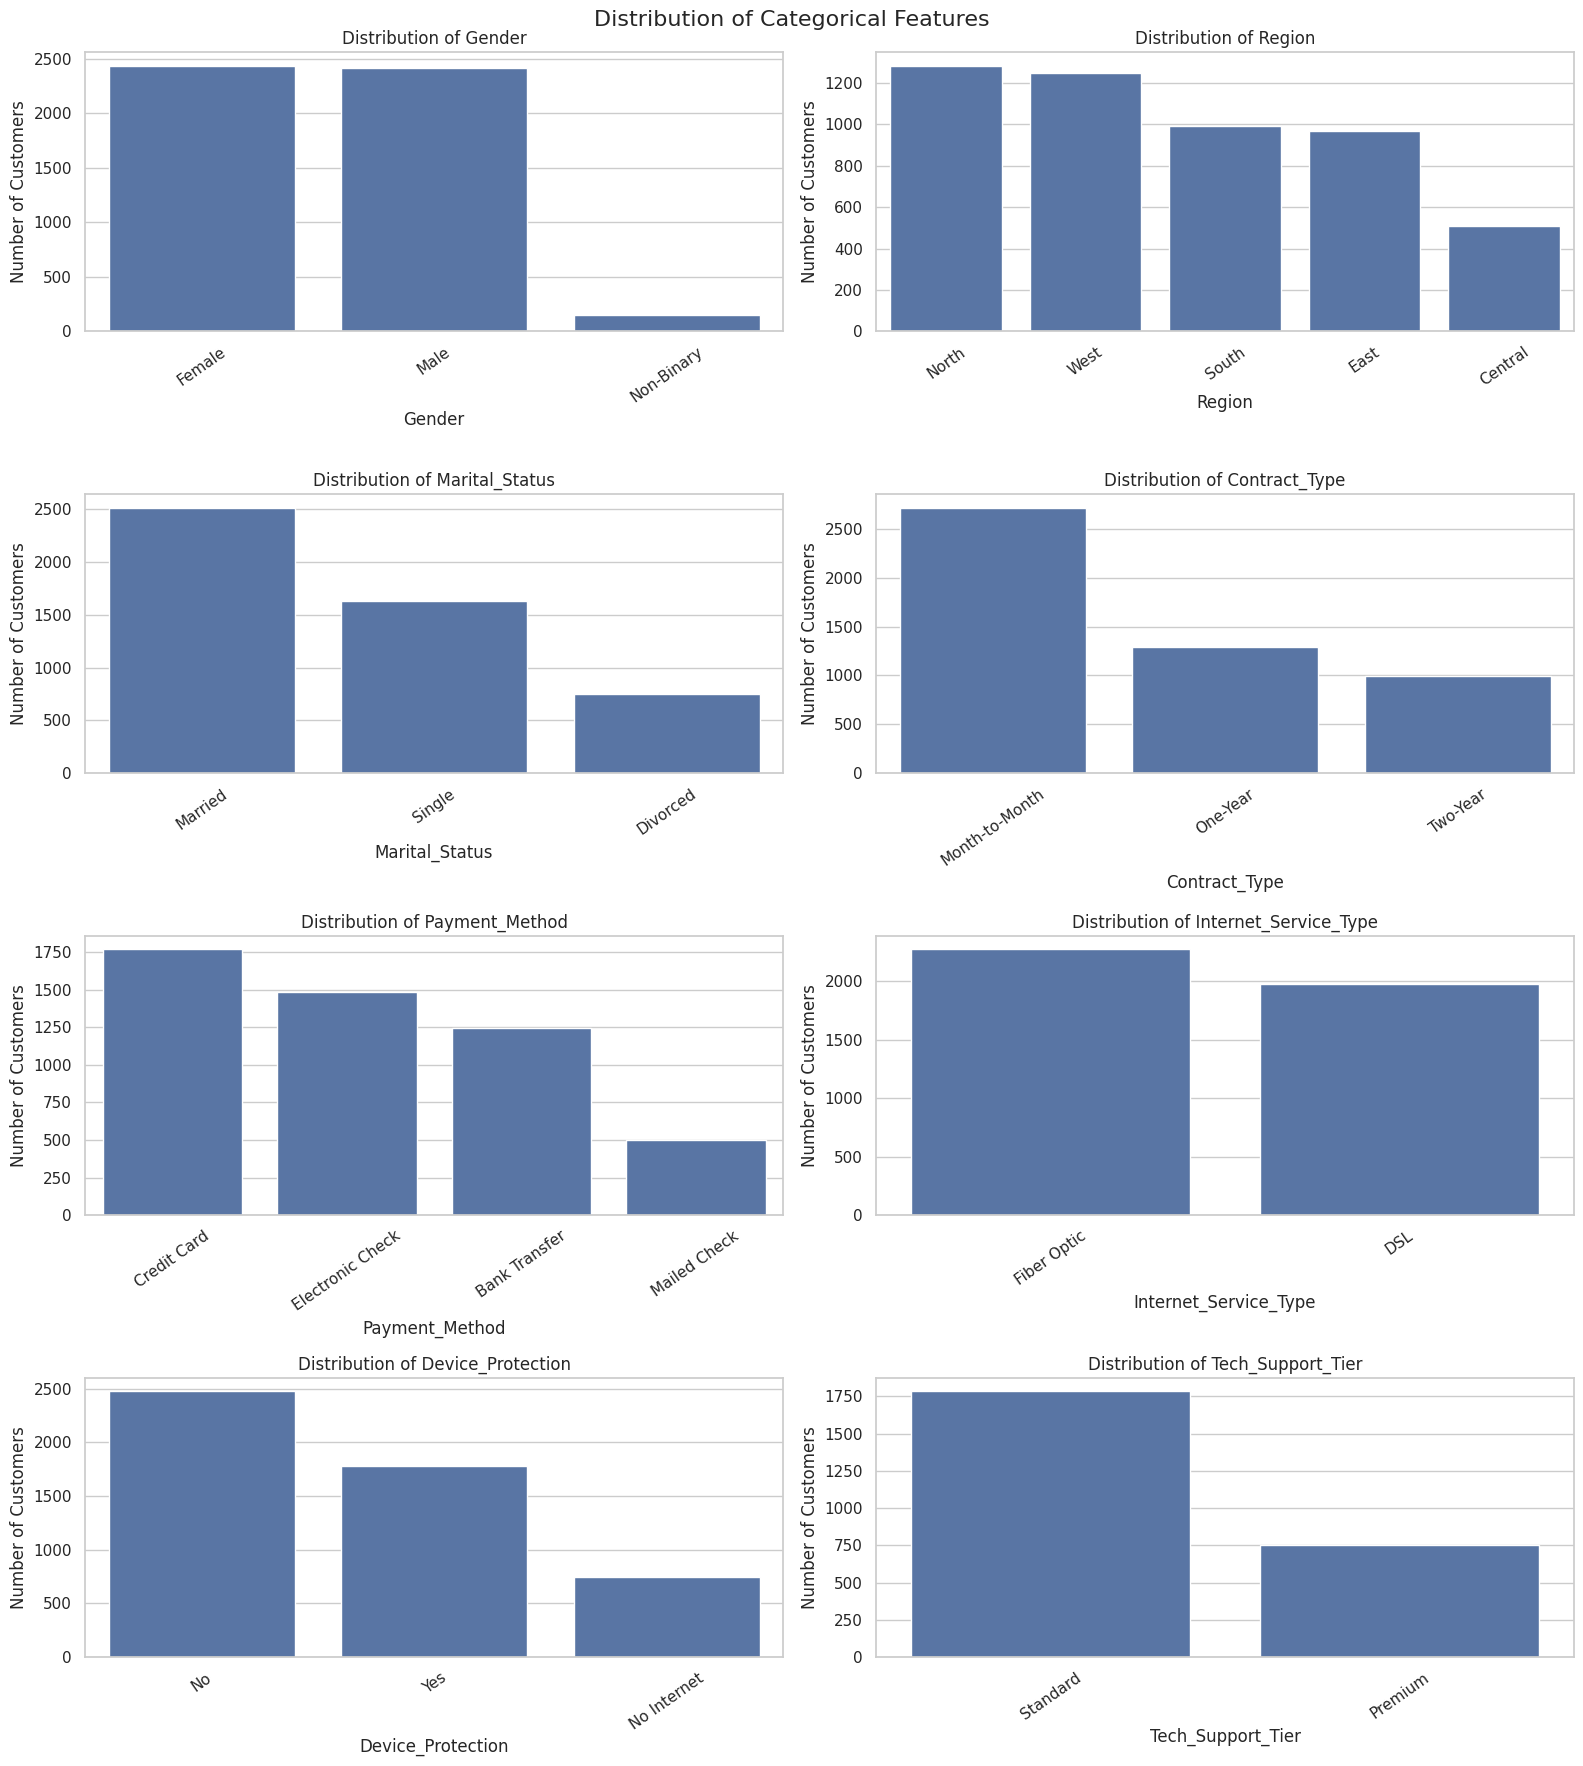

In [7]:

# Identify categorical features

categorical_columns = [
    "Gender",
    "Region",
    "Marital_Status",
    "Contract_Type",
    "Payment_Method",
    "Internet_Service_Type",
    "Device_Protection",
    "Tech_Support_Tier"
]

# Display frequency distributions

for column in categorical_columns:
    print(f"\nDistribution of {column}:")
    display(
        df[column]
        .value_counts(dropna=False)
        .to_frame("Count")
    )



# Visualize categorical feature distributions

fig, axes = plt.subplots(4, 2, figsize=(16, 18))

axes = axes.flatten()

for i, column in enumerate(categorical_columns):

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Number of Customers")
    axes[i].tick_params(axis="x", rotation=35)

plt.suptitle(
    "Distribution of Categorical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


### 1.8 Target Variable Analysis

The target variable in this dataset is `Churn`.

It represents whether a customer has discontinued the service:

- 0: Customer retained.
- 1: Customer churned.

Analysing its distribution helps us understand the proportion of retained and churned customers and determine whether the target classes are imbalanced.

A frequency table and countplot are used to examine the distribution.

,Customer Count,Percentage
Retained (0),2651,53.02
Churned (1),2349,46.98


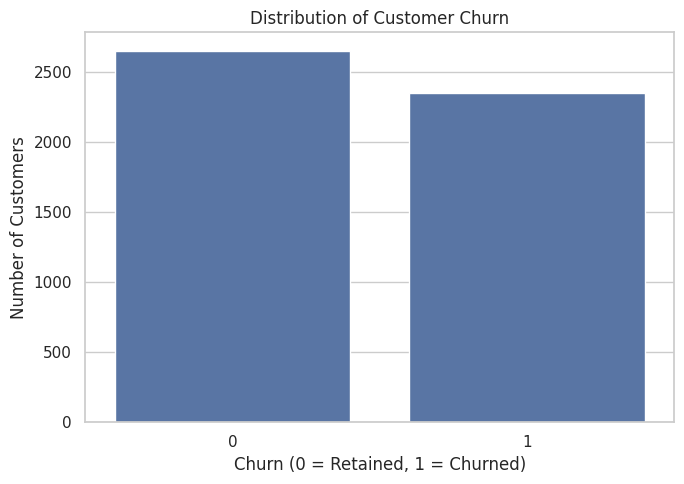

In [8]:

# Calculate churn frequency and percentage

churn_summary = pd.DataFrame({
    "Customer Count": df["Churn"].value_counts().sort_index(),
    "Percentage": (
        df["Churn"].value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

churn_summary.index = ["Retained (0)", "Churned (1)"]

display(churn_summary)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Distribution of Customer Churn")
plt.xlabel("Churn (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


### 1.9 Correlation Analysis

Correlation analysis is used to examine the relationships between numerical features.

We use the Pearson correlation coefficient, which measures the strength and direction of a linear relationship between two variables.

Its values range from -1 to +1:

- **+1:** Perfect positive correlation.
- **-1:** Perfect negative correlation.
- **0:** No linear correlation.

A correlation heatmap provides a visual representation of these relationships.

This analysis helps identify highly correlated features that may contain overlapping information. Such features will be investigated further during feature selection.

Correlation does not imply causation, and highly correlated features will not automatically be removed.

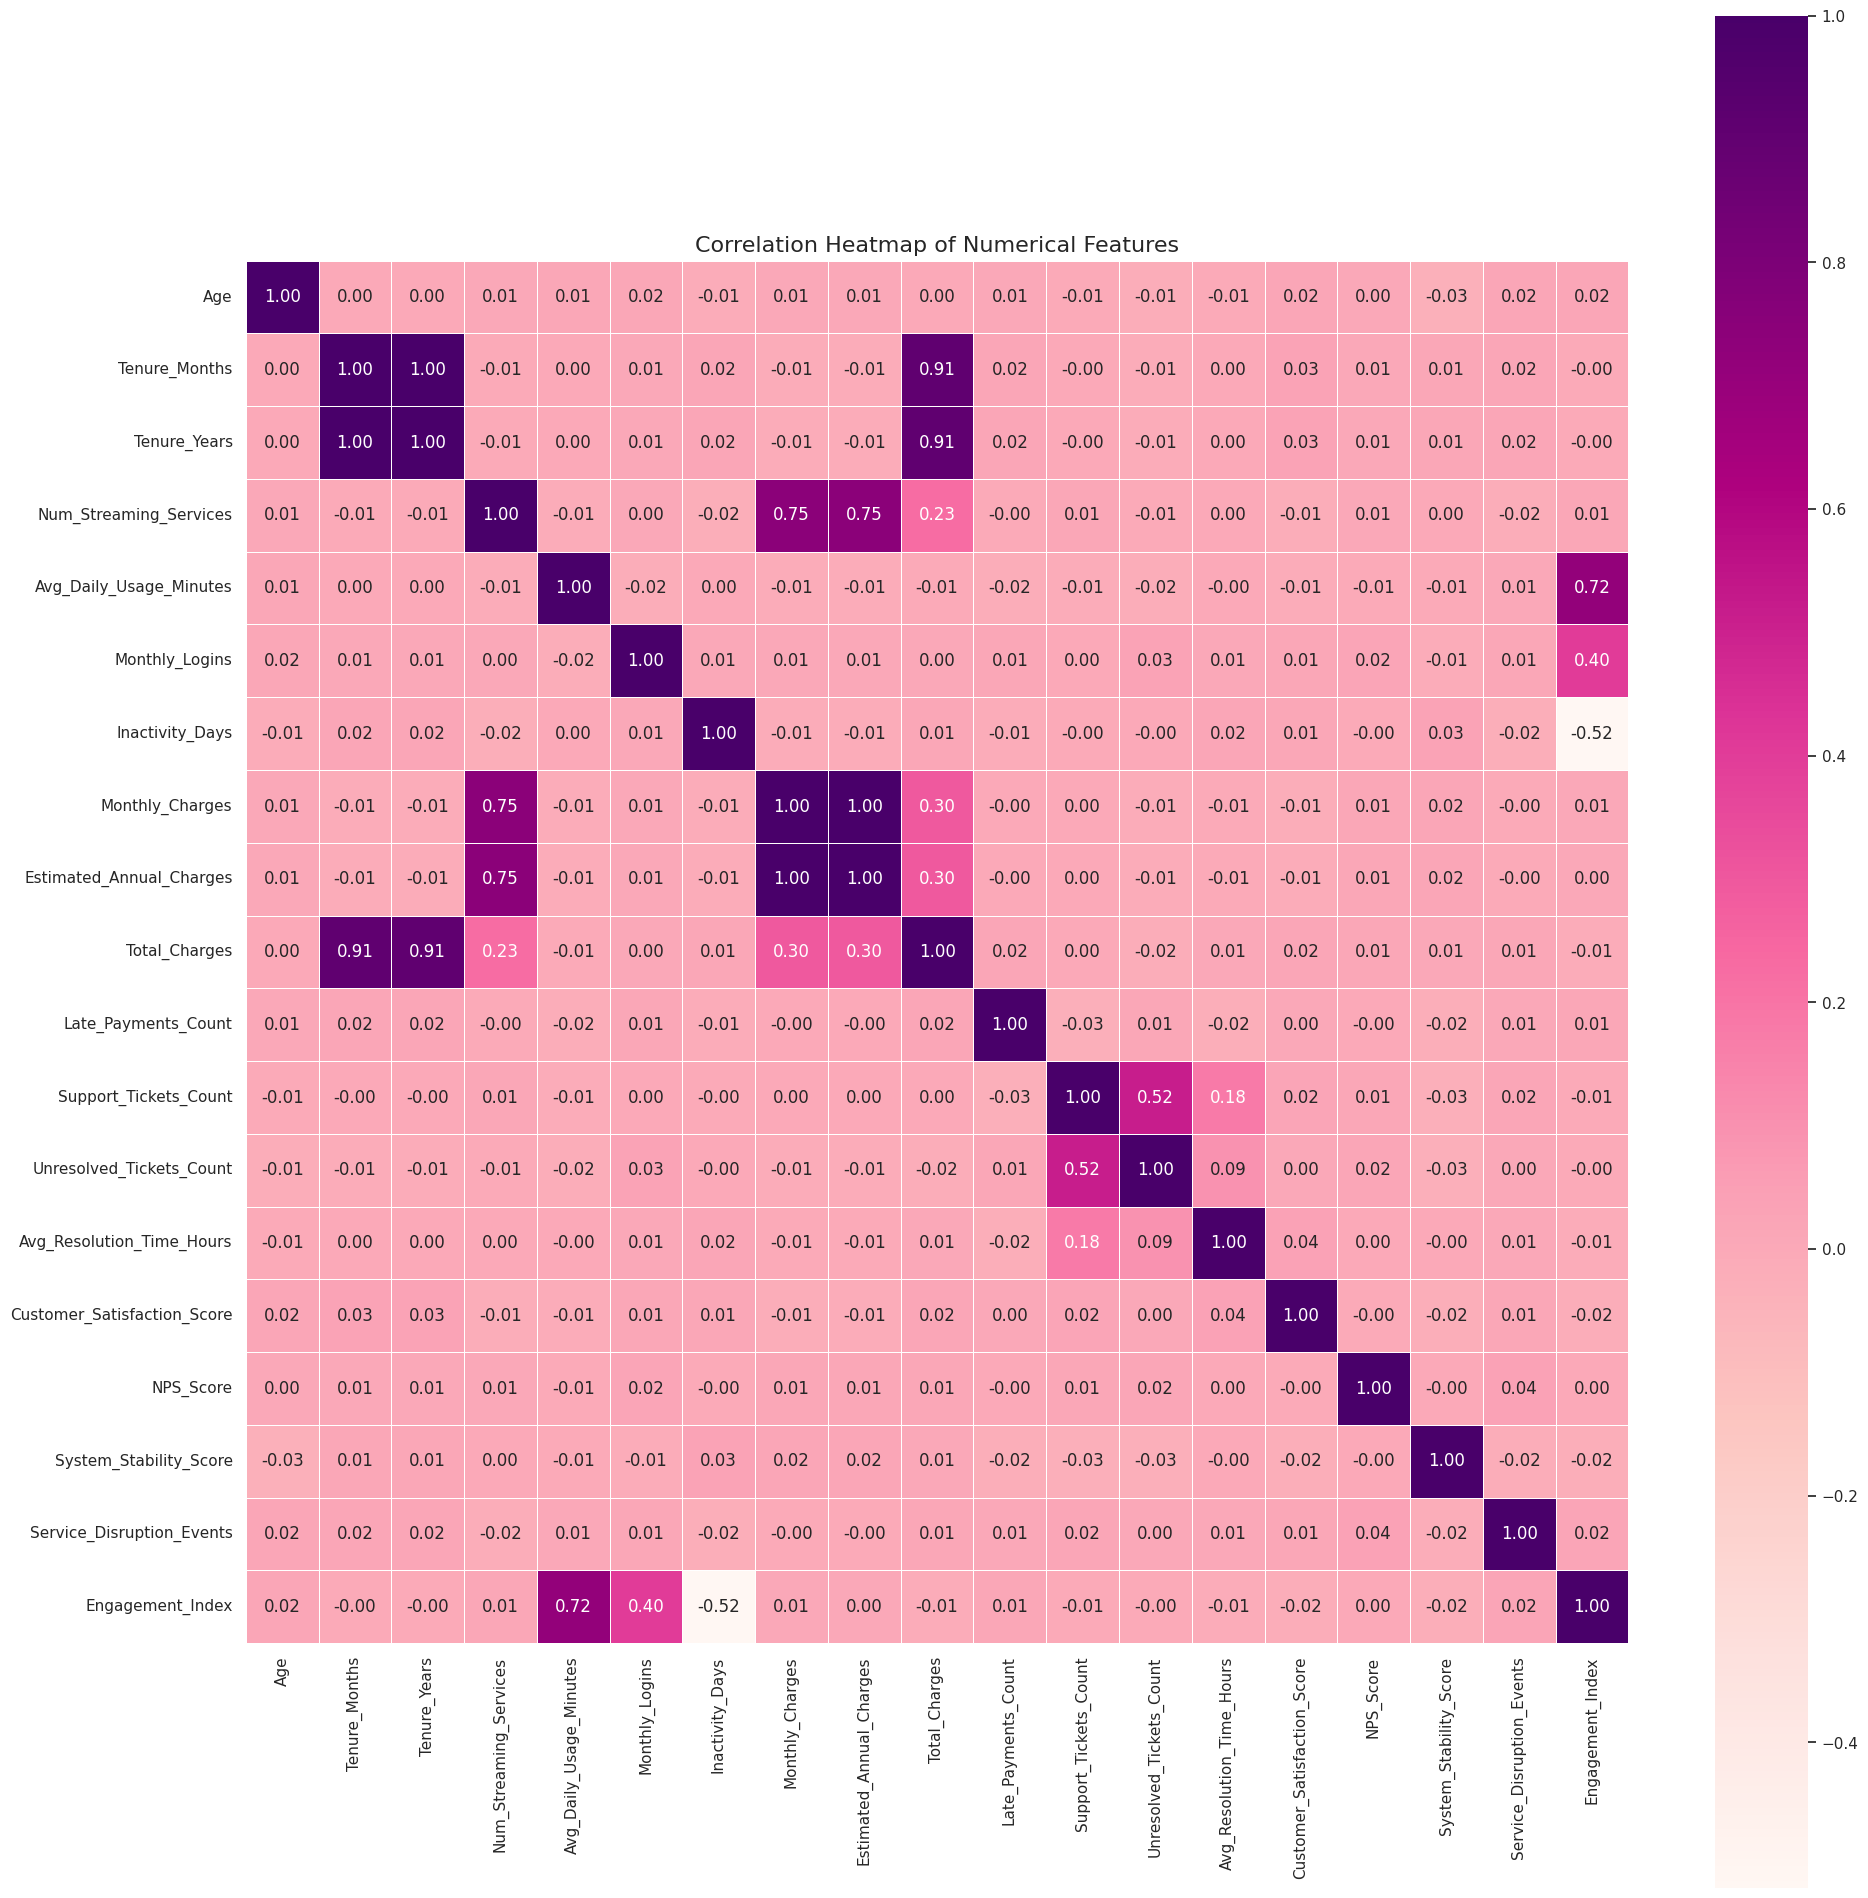

In [9]:

# Select numerical features (excluding the target variable)
numerical_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Remove target variable and numerical identifiers if present
numerical_features = [
    col for col in numerical_features
    if col not in ["Churn", "Customer_ID"]
]

# Calculate Pearson correlation
correlation_matrix = df[numerical_features].corr(method="pearson")

# Create a magenta correlation heatmap
plt.figure(figsize=(20, 20))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="RdPu",
    fmt=".2f",
    linewidths=0.5,
    square=True
)

plt.title("Correlation Heatmap of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()


### 1.10 Key Observations from Exploratory Analysis

- **Dataset:** 5,000 customers and 32 columns. Churn is fairly balanced (2,349 churned, 46.98%), so no resampling is needed.
- **Missing values:** 7 columns have missing values (4,249 entries in total). `Tech_Support_Tier` (49.28%) and `Internet_Service_Type` (14.96%) are the most affected. The other five columns are below 7%.
- **Skewness:** `Avg_Resolution_Time_Hours` (3.66), `Avg_Daily_Usage_Minutes` (3.19), `Inactivity_Days` (1.66) and `Total_Charges` (1.56) are strongly right-skewed. This motivates a log transformation.
- **Outliers:** `Avg_Daily_Usage_Minutes` reaches 969.7 against a median of 109. Most flagged outliers are plausible customer behaviour, not errors, so they are kept and handled by the log transformation instead of being deleted.
- **Redundancy:** `Tenure_Months` and `Tenure_Years` (r = 0.9998) and `Monthly_Charges` and `Estimated_Annual_Charges` (r = 0.9994) carry the same information. `Total_Charges` is correlated with tenure (r = 0.91), which is expected because it accumulates over time.
- **Identifier:** `Customer_ID` has no predictive meaning and will be excluded.

These observations drive the decisions in Parts B and C.

# Part B: Data Preprocessing

The dataset contains missing values, categorical variables, and numerical features with different scales. These need to be handled before the data can be used for machine learning.

### Missing Value Treatment

Seven columns contain missing values. Median imputation is used for the four numerical columns because it is less sensitive to outliers. Marital_Status is filled using the most frequent category, while missing values in Tech_Support_Tier and Internet_Service_Type are retained as a separate "Missing" category.

### Categorical Encoding

One-hot encoding is applied to categorical features so that they can be represented numerically without introducing an artificial order. Customer_ID is removed because it is an identifier rather than a useful predictive feature.

### Numerical Scaling

StandardScaler is used to standardize numerical features. This places features with different units on a comparable scale and is useful for algorithms that are sensitive to feature magnitude.

### Preprocessing Pipeline

The dataset is divided into training and testing sets before fitting the preprocessing transformations. Missing-value treatment, encoding, and scaling are fitted using only the training data to avoid data leakage.

The before-and-after visualizations illustrate the reduction in missing values and the effect of scaling on selected numerical features.

BEFORE PREPROCESSING
Training shape: (4000, 30)
Missing values: 3372

AFTER PREPROCESSING
Training shape: (4000, 54)
Missing values: 0

Test shape: (1000, 54)


,median_numeric__Avg_Resolution_Time_Hours,median_numeric__Customer_Satisfaction_Score,median_numeric__Engagement_Index,median_numeric__Total_Charges,other_numeric__Age,other_numeric__Tenure_Months,other_numeric__Tenure_Years,other_numeric__Num_Streaming_Services,other_numeric__Avg_Daily_Usage_Minutes,other_numeric__Monthly_Logins,...,other_category__Paperless_Billing_Yes,other_category__Device_Protection_No,other_category__Device_Protection_No Internet,other_category__Device_Protection_Yes,other_category__Charge_Band_Budget,other_category__Charge_Band_Moderate,other_category__Charge_Band_Premium,other_category__Tenure_Segment_Established,other_category__Tenure_Segment_Loyal,other_category__Tenure_Segment_New
4331,-0.940068,-1.862560,1.309577,-0.806875,-1.179253,-0.905154,-0.925938,0.281780,0.733544,0.695211,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
3323,0.519482,-1.862560,0.670649,0.315300,0.284374,0.101495,0.101003,1.093243,0.599063,-0.486719,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
1539,-0.366446,-0.054688,-1.416846,-0.315221,-1.954115,-0.452162,-0.442672,0.281780,0.221395,-0.959491,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3255,0.226297,0.849248,-0.221871,1.296051,0.112183,0.906815,0.886310,0.281780,0.108207,-0.250333,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1160,-0.264469,0.849248,-0.405571,-0.579385,-1.954115,-0.502494,-0.503080,-1.341145,-0.745748,0.222439,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


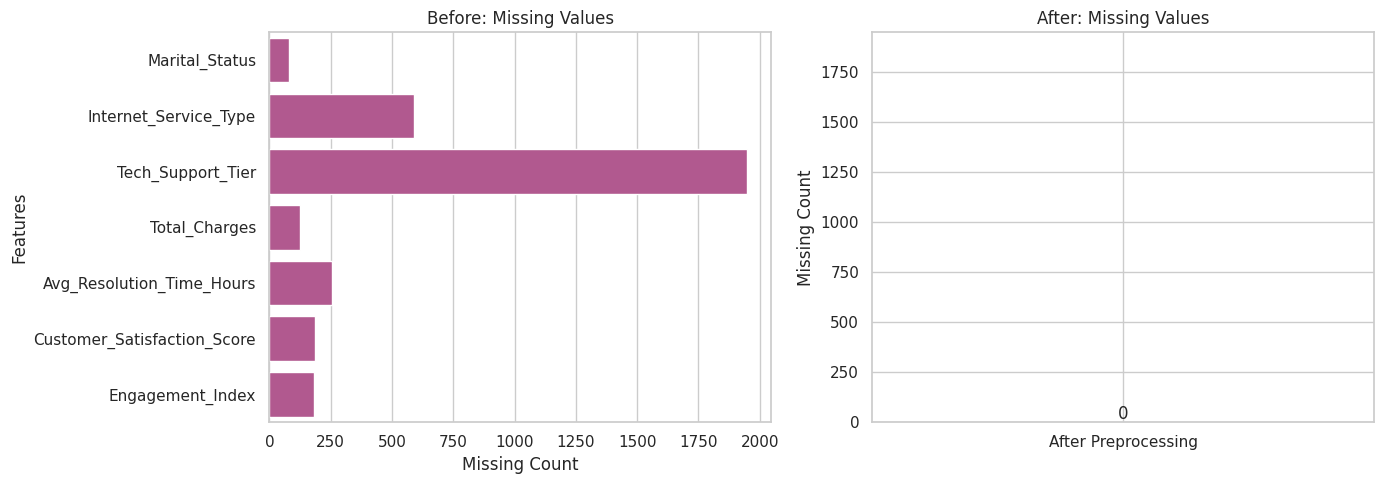

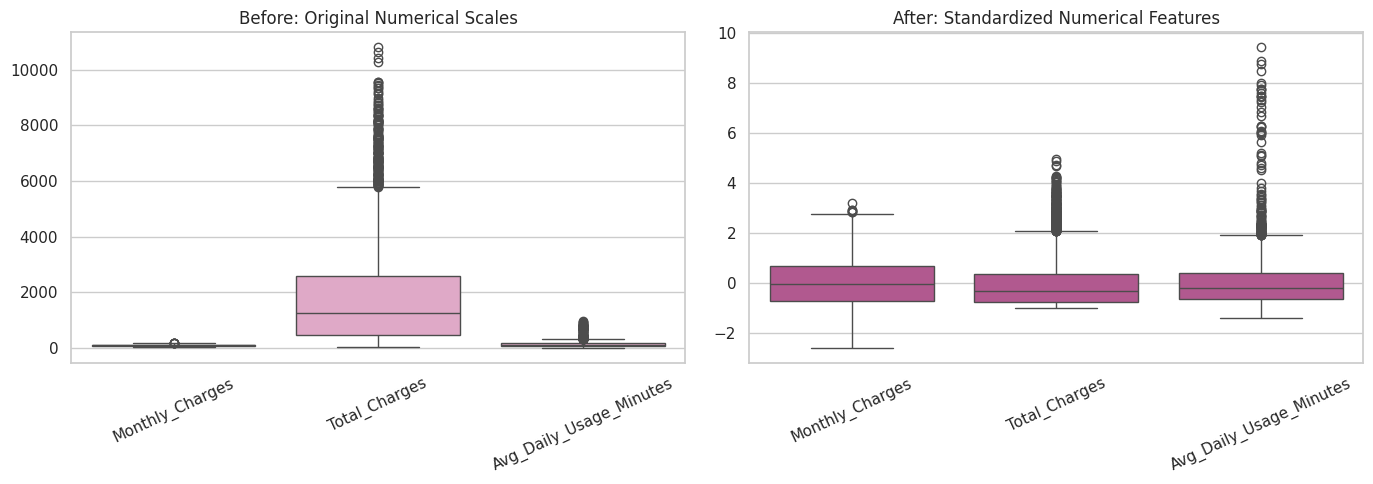

In [10]:

# PART B: DATA PREPROCESSING

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Separate features and target
X = df.drop(columns=["Customer_ID", "Churn"])
y = df["Churn"]

#Train-test split before preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

#Define column groups
median_cols = [
    "Avg_Resolution_Time_Hours",
    "Customer_Satisfaction_Score",
    "Engagement_Index",
    "Total_Charges"
]

mode_cols = ["Marital_Status"]

missing_category_cols = [
    "Tech_Support_Tier",
    "Internet_Service_Type"
]

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

other_categorical_cols = [
    col for col in categorical_cols
    if col not in mode_cols + missing_category_cols
]

other_numeric_cols = [
    col for col in numeric_cols
    if col not in median_cols
]

#Create preprocessing pipelines
median_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

mode_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

missing_category_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

#Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("median_numeric", median_pipeline, median_cols),
    ("other_numeric", numeric_pipeline, other_numeric_cols),
    ("mode_category", mode_pipeline, mode_cols),
    ("missing_category", missing_category_pipeline,
     missing_category_cols),
    ("other_category", categorical_pipeline,
     other_categorical_cols)
], sparse_threshold=0)

#Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("BEFORE PREPROCESSING")
print("Training shape:", X_train.shape)
print("Missing values:", X_train.isna().sum().sum())

print("\nAFTER PREPROCESSING")
print("Training shape:", X_train_processed.shape)
print("Missing values:", X_train_processed.isna().sum().sum())

print("\nTest shape:", X_test_processed.shape)

display(X_train_processed.head())

#visual 1: Missing values before and after
missing_before = X_train.isna().sum()
missing_before = missing_before[missing_before > 0]

missing_after = X_train_processed.isna().sum().sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    x=missing_before.values,
    y=missing_before.index,
    color="#C04A92",
    ax=axes[0]
)
axes[0].set_title("Before: Missing Values")
axes[0].set_xlabel("Missing Count")
axes[0].set_ylabel("Features")

axes[1].bar(
    ["After Preprocessing"],
    [missing_after],
    color="#C04A92"
)
axes[1].set_title("After: Missing Values")
axes[1].set_ylabel("Missing Count")
axes[1].set_ylim(0, max(missing_before.max(), 1))
axes[1].text(
    0, missing_after + 15,
    str(missing_after),
    ha="center"
)

plt.tight_layout()
plt.show()

#Visual 2: Numerical scaling before and after
scale_features = [
    "Monthly_Charges",
    "Total_Charges",
    "Avg_Daily_Usage_Minutes"
]

before_scale = X_train[scale_features].copy()

after_scale = pd.DataFrame({
    col: X_train_processed[
        "median_numeric__" + col
        if col in median_cols
        else "other_numeric__" + col
    ]
    for col in scale_features
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=before_scale,
    color="#E8A0C8",
    ax=axes[0]
)
axes[0].set_title("Before: Original Numerical Scales")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(
    data=after_scale,
    color="#C04A92",
    ax=axes[1]
)
axes[1].set_title("After: Standardized Numerical Features")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


### Skewness Treatment and Alternatives Considered

Four features are strongly right-skewed (skewness > 1.5). A `log1p` transformation is applied to them before scaling, because it compresses extreme values without deleting any customer. `log1p` is used instead of `log` because some features contain zeros.

**Alternatives considered:**
- *Mean or KNN/iterative imputation:* mean is more sensitive to outliers. KNN and iterative imputation are more complex, and their benefit is not guaranteed here.
- *Ordinal encoding for `Tech_Support_Tier`:* Standard < Premium looks ordered, but the 49% "Missing" group has no natural position in that order, so one-hot encoding is safer.
- *Removing or winsorizing outliers:* rejected, because the extreme values look like genuine heavy usage and removing them would lose real customers.
- *PowerTransformer (Yeo-Johnson):* a valid option, but `log1p` is simpler and easier to explain.

,Skew Before,Skew After log1p
Avg_Daily_Usage_Minutes,3.19,-0.42
Avg_Resolution_Time_Hours,3.66,-0.75
Total_Charges,1.56,-0.56
Inactivity_Days,1.66,-0.07


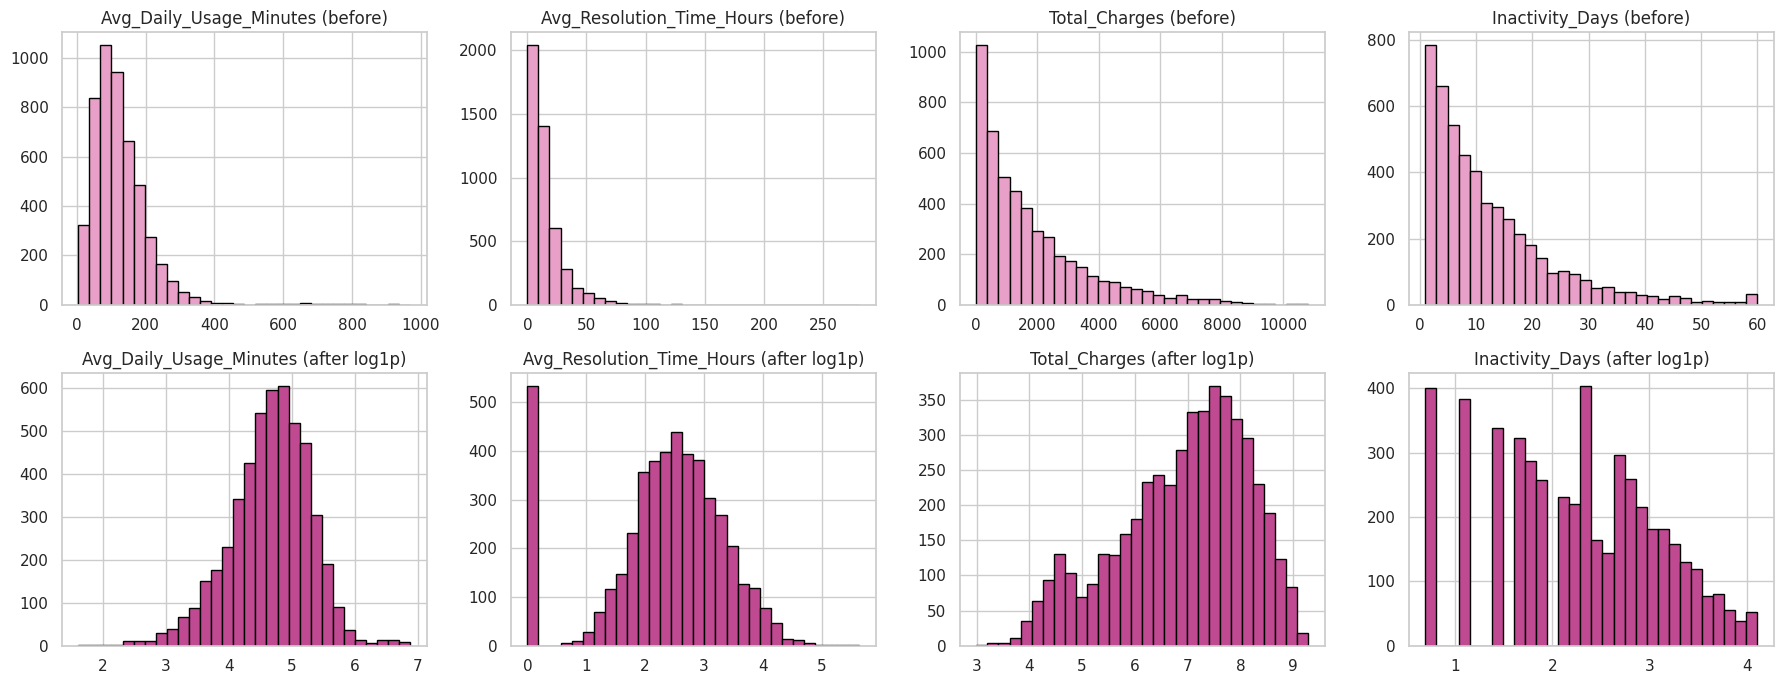

In [16]:
# Skewness before and after log1p transformation
log_cols = [
    "Avg_Daily_Usage_Minutes",
    "Avg_Resolution_Time_Hours",
    "Total_Charges",
    "Inactivity_Days"
]

skew_check = pd.DataFrame({
    "Skew Before": df[log_cols].skew(),
    "Skew After log1p": np.log1p(df[log_cols]).skew()
}).round(2)

display(skew_check)

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(log_cols):
    axes[0, i].hist(df[col].dropna(), bins=30, color="#E8A0C8", edgecolor="black")
    axes[0, i].set_title(f"{col} (before)")
    axes[1, i].hist(np.log1p(df[col].dropna()), bins=30, color="#C04A92", edgecolor="black")
    axes[1, i].set_title(f"{col} (after log1p)")
plt.tight_layout()
plt.show()

#Part C: Feature Engineering and Selection

### 3.1 Feature Construction

New features are created from existing variables to capture customer behaviour that single columns do not show:

- **Support_Ticket_Rate:** support tickets per month of tenure. A customer with 4 tickets in 3 months is under more strain than one with 4 tickets in 40 months.
- **Late_Payment_Rate:** late payments per month of tenure. This is a billing-reliability signal that may indicate financial stress or dissatisfaction.
- **Unresolved_Ticket_Ratio:** share of tickets left unresolved. Unresolved problems are a plausible driver of churn.

A fourth candidate, **Charges_Per_Month** (Total_Charges / Tenure_Months), was also tested but **rejected**: its correlation with `Monthly_Charges` is 0.99, so it only duplicates an existing feature.

Zero denominators are replaced with 0, meaning "no tenure" or "no tickets, so no unresolved ratio". Missing values in the source columns are not filled with 0 here. Only zero denominators are, so the later pipeline imputation stays correct.

In [17]:
# FEATURE CONSTRUCTION
df_features = df.copy()

tenure = df_features["Tenure_Months"].replace(0, np.nan)
tickets = df_features["Support_Tickets_Count"].replace(0, np.nan)

df_features["Support_Ticket_Rate"] = (df_features["Support_Tickets_Count"] / tenure).fillna(0)
df_features["Late_Payment_Rate"] = (df_features["Late_Payments_Count"] / tenure).fillna(0)
df_features["Unresolved_Ticket_Ratio"] = (df_features["Unresolved_Tickets_Count"] / tickets).fillna(0)

new_features = ["Support_Ticket_Rate", "Late_Payment_Rate", "Unresolved_Ticket_Ratio"]
display(df_features[new_features].head())

# Candidate tested and rejected
candidate = df["Total_Charges"] / df["Tenure_Months"]
print("Charges_Per_Month vs Monthly_Charges correlation:",
      round(candidate.corr(df["Monthly_Charges"]), 3), "-> redundant, not used")

print("Original dataset shape:", df.shape)
print("Dataset with new features:", df_features.shape)

,Support_Ticket_Rate,Late_Payment_Rate,Unresolved_Ticket_Ratio
0,0.044444,0.022222,0.5
1,0.166667,0.000000,0.0
2,0.095238,0.047619,0.0
3,0.021739,0.065217,0.0
4,0.166667,0.000000,0.0


Charges_Per_Month vs Monthly_Charges correlation: 0.991 -> redundant, not used
Original dataset shape: (5000, 32)
Dataset with new features: (5000, 35)


### 3.2 Redundant Feature Identification

Highly correlated features may contain similar information. Pearson correlation is used to identify numerical feature pairs with an absolute correlation greater than 0.85.

The results are examined before removing features, since high correlation alone does not necessarily mean a feature is unimportant.

Features that duplicate existing information can be removed to simplify the dataset and reduce unnecessary complexity.

Highly correlated feature pairs:


,Feature 1,Feature 2,Correlation
21,Tenure_Months,Tenure_Years,0.999848
126,Monthly_Charges,Estimated_Annual_Charges,0.999444
28,Tenure_Months,Total_Charges,0.908100
47,Tenure_Years,Total_Charges,0.908090


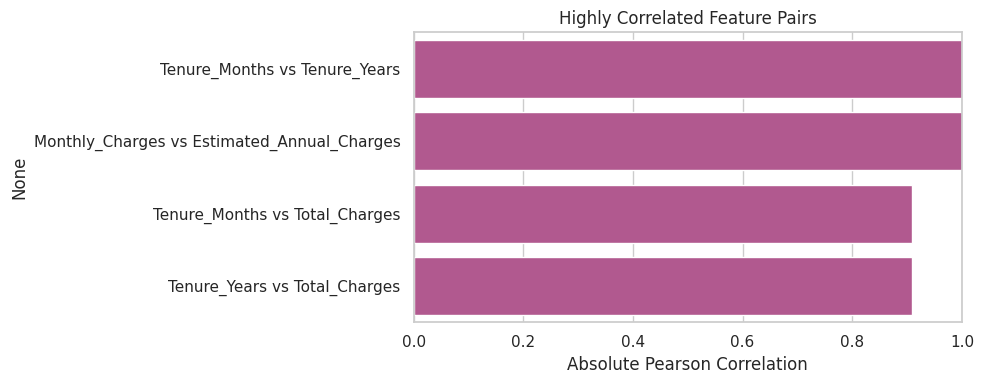

In [12]:

#REDUNDANT FEATURE ANALYSIS

# Select numerical features, excluding the target
numeric_data = df_features.select_dtypes(include=np.number)
numeric_data = numeric_data.drop(columns=["Churn"], errors="ignore")

# Calculate absolute Pearson correlations
corr_matrix = numeric_data.corr().abs()

# Keep only the upper triangle to avoid duplicate pairs
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Identify highly correlated feature pairs
high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1", "Feature 2", "Correlation"
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Correlation"] > 0.85
].sort_values("Correlation", ascending=False)

print("Highly correlated feature pairs:")
display(high_corr_pairs)

# Visualize the identified correlations
if not high_corr_pairs.empty:
    plt.figure(figsize=(10, 4))

    labels = (
        high_corr_pairs["Feature 1"] +
        " vs " +
        high_corr_pairs["Feature 2"]
    )

    sns.barplot(
        x=high_corr_pairs["Correlation"],
        y=labels,
        color="#C04A92"
    )

    plt.title("Highly Correlated Feature Pairs")
    plt.xlabel("Absolute Pearson Correlation")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.show()
else:
    print("No feature pairs exceed the 0.85 threshold.")


**Findings:** four pairs exceed 0.85:
- `Tenure_Months` vs `Tenure_Years` (0.9998): identical information in different units, so `Tenure_Years` is dropped.
- `Monthly_Charges` vs `Estimated_Annual_Charges` (0.9994): the annual figure is exactly 12 × monthly, so `Estimated_Annual_Charges` is dropped.
- `Tenure_Months` vs `Total_Charges` (0.91) and `Tenure_Years` vs `Total_Charges` (0.91): expected, because total charges accumulate with tenure. `Total_Charges` is kept since it measures customer value, which tenure alone does not.

### 3.3 Feature Selection

Feature selection helps reduce unnecessary complexity by retaining relevant information and removing redundant variables.

Three columns are removed: `Customer_ID` (identifier), `Tenure_Years` (duplicate of `Tenure_Months`) and `Estimated_Annual_Charges` (exactly 12 × `Monthly_Charges`). `Total_Charges` is kept despite its 0.91 correlation with tenure, because it adds information about customer value. The three engineered features are kept because they are not strongly correlated with any existing feature.

In [18]:
# FEATURE SELECTION
features_to_drop = ["Customer_ID", "Tenure_Years", "Estimated_Annual_Charges"]

df_selected = df_features.drop(columns=features_to_drop, errors="ignore")
X_selected = df_selected.drop(columns=["Churn"])
y_selected = df_selected["Churn"]

print("Before feature selection:", df_features.shape)
print("After feature selection:", df_selected.shape)
print("\nRemoved features:", features_to_drop)
print("\nEngineered features retained:", ["Support_Ticket_Rate", "Late_Payment_Rate", "Unresolved_Ticket_Ratio"])
print("\nRemaining predictor features:", X_selected.shape[1])
display(X_selected.head())

Before feature selection: (5000, 35)
After feature selection: (5000, 32)

Removed features: ['Customer_ID', 'Tenure_Years', 'Estimated_Annual_Charges']

Engineered features retained: ['Support_Ticket_Rate', 'Late_Payment_Rate', 'Unresolved_Ticket_Ratio']

Remaining predictor features: 31


,Age,Gender,Region,Marital_Status,Tenure_Months,Contract_Type,Payment_Method,Paperless_Billing,Internet_Service_Type,Device_Protection,...,Customer_Satisfaction_Score,NPS_Score,System_Stability_Score,Service_Disruption_Events,Engagement_Index,Charge_Band,Tenure_Segment,Support_Ticket_Rate,Late_Payment_Rate,Unresolved_Ticket_Ratio
0,46,Female,South,Single,45,One-Year,Credit Card,Yes,NaN,No Internet,...,2.0,1,4,1,NaN,Moderate,Loyal,0.044444,0.022222,0.5
1,39,Female,North,Single,6,Month-to-Month,Electronic Check,Yes,Fiber Optic,No Internet,...,2.0,9,4,2,43.77,Premium,New,0.166667,0.000000,0.0
2,48,Female,West,Married,21,Month-to-Month,Mailed Check,Yes,DSL,Yes,...,3.0,2,2,1,25.17,Moderate,Established,0.095238,0.047619,0.0
3,59,Female,South,Married,46,Month-to-Month,Credit Card,Yes,Fiber Optic,Yes,...,3.0,4,3,1,49.03,Moderate,Loyal,0.021739,0.065217,0.0
4,38,Female,South,Single,12,Month-to-Month,Mailed Check,Yes,NaN,No,...,5.0,5,5,1,58.83,Moderate,New,0.166667,0.000000,0.0


#Part D: Dimensionality Reduction

### 4.1 Principal Component Analysis (PCA)

Principal Component Analysis (PCA) is a dimensionality reduction technique that transforms numerical features into a smaller set of components while retaining as much variance as possible.

PCA is useful when a dataset contains correlated features or a large number of encoded variables. However, the resulting components are less interpretable than the original customer features.

We will examine how many principal components are required to preserve 95% of the variance. This will help determine whether PCA is appropriate for the churn dataset.

PCA will be fitted only on the training data to prevent data leakage.

Features before PCA: 55
Components after PCA: 32
Variance retained: 95.67 %
Dimensionality reduction: 41.8 %


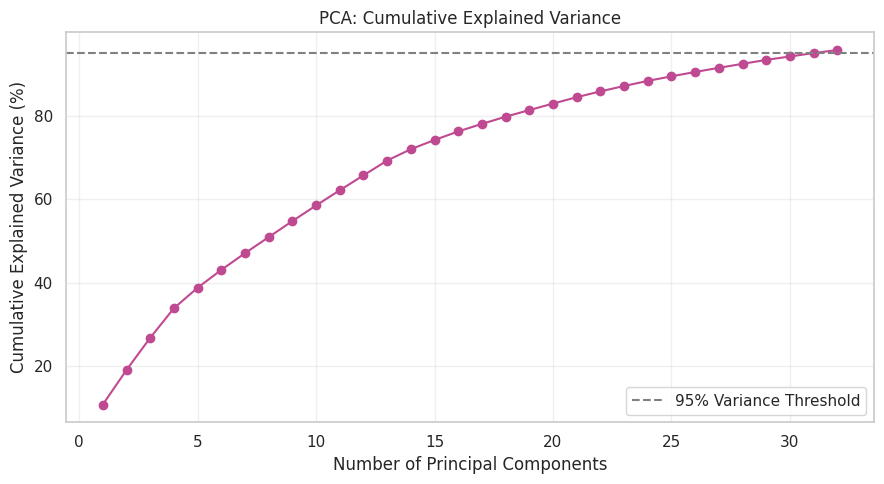

In [19]:
# PREPROCESSING + PCA PIPELINE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA


# 1. Feature construction + removal of redundant columns
class FeatureBuilder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        tenure = X["Tenure_Months"].replace(0, np.nan)
        tickets = X["Support_Tickets_Count"].replace(0, np.nan)

        # Only zero denominators become 0; missing source values stay NaN
        X["Support_Ticket_Rate"] = (X["Support_Tickets_Count"] / tenure).fillna(0)
        X["Late_Payment_Rate"] = (X["Late_Payments_Count"] / tenure).fillna(0)
        X["Unresolved_Ticket_Ratio"] = (X["Unresolved_Tickets_Count"] / tickets).fillna(0)

        return X.drop(
            columns=["Customer_ID", "Tenure_Years", "Estimated_Annual_Charges"],
            errors="ignore"
        )


# 2. Split BEFORE fitting anything
X_raw = df.drop(columns=["Churn"])
y_raw = df["Churn"]

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_raw, y_raw, test_size=0.20, random_state=42, stratify=y_raw
)

# 3. Column groups (derived from the constructed feature set)
X_sample = FeatureBuilder().transform(X_train_d.head(5))

log_cols_d = [
    "Avg_Daily_Usage_Minutes", "Avg_Resolution_Time_Hours",
    "Total_Charges", "Inactivity_Days"
]
numeric_cols_d = X_sample.select_dtypes(include=np.number).columns.tolist()
other_numeric_cols_d = [c for c in numeric_cols_d if c not in log_cols_d]
categorical_cols_d = [c for c in X_sample.columns if c not in numeric_cols_d]

missing_category_cols_d = ["Tech_Support_Tier", "Internet_Service_Type"]
other_categorical_cols_d = [c for c in categorical_cols_d if c not in missing_category_cols_d]

# 4. Transformers
log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

missing_category_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

category_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor_d = ColumnTransformer([
    ("log_numeric", log_pipeline, log_cols_d),
    ("numeric", numeric_pipeline, other_numeric_cols_d),
    ("missing_category", missing_category_pipeline, missing_category_cols_d),
    ("category", category_pipeline, other_categorical_cols_d)
])

# 5. Full pipeline: construction -> preprocessing -> PCA
pca_pipeline = Pipeline([
    ("feature_construction", FeatureBuilder()),
    ("preprocessing", preprocessor_d),
    ("pca", PCA(n_components=0.95, random_state=42))
])

# 6. Fit on training data only
X_train_pca = pca_pipeline.fit_transform(X_train_d, y_train_d)
X_test_pca = pca_pipeline.transform(X_test_d)

# 7. Preprocessing-only version (same fitted steps, no PCA) for interpretability
preprocessing_only = Pipeline(pca_pipeline.steps[:-1])
X_train_prep = preprocessing_only.transform(X_train_d)

# 8. Results
pca_model = pca_pipeline.named_steps["pca"]
print("Features before PCA:", X_train_prep.shape[1])
print("Components after PCA:", pca_model.n_components_)
print("Variance retained:", round(pca_model.explained_variance_ratio_.sum() * 100, 2), "%")
print("Dimensionality reduction:",
      round((1 - pca_model.n_components_ / X_train_prep.shape[1]) * 100, 1), "%")

# 9. Cumulative explained variance
cumulative_variance = np.cumsum(pca_model.explained_variance_ratio_)
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance * 100,
         marker="o", color="#C04A92")
plt.axhline(y=95, color="gray", linestyle="--", label="95% Variance Threshold")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA: Cumulative Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### PCA Results and Interpretation

PCA was fitted on the preprocessed training data. The **55** features were reduced to **32** principal components, retaining **95.67%** of the variance, a reduction of about **41.8%**.

The reduction is moderate, not dramatic. Most one-hot encoded columns are nearly independent, so PCA cannot compress them much. The components also lose direct business meaning ("what does component 7 mean?"). PCA is therefore treated as an optional compact representation, and the preprocessed (non-PCA) features remain the main option when interpretability matters. Whether PCA helps churn prediction has not been tested.

### 4.2 Reusable Preprocessing Pipeline

A reusable preprocessing pipeline combines missing-value imputation, categorical encoding, numerical scaling, and dimensionality reduction into a consistent workflow.

The pipeline is fitted on the training set only and can then be applied to test data or new customer records without refitting. It chains four stages: **feature construction** (3 ratios, drop redundant columns) → **imputation** (median, most frequent, or a "Missing" category) → **transformation and encoding** (log1p and scaling for numeric, one-hot for categorical) → **PCA** (optional final step).

Two versions are saved: the full pipeline with PCA, and a preprocessing-only version that keeps the original interpretable features.

In [20]:
# SAVE AND TEST BOTH PIPELINES
import joblib

joblib.dump(pca_pipeline, "churn_pipeline_with_pca.pkl")
joblib.dump(preprocessing_only, "churn_preprocessing_pipeline.pkl")
print("Pipelines saved successfully!")

loaded_pca = joblib.load("churn_pipeline_with_pca.pkl")
loaded_prep = joblib.load("churn_preprocessing_pipeline.pkl")

sample_customers = X_test_d.head(5)
print("Raw customer records:", sample_customers.shape[0])
print("Preprocessing only:", loaded_prep.transform(sample_customers).shape)
print("With PCA:          ", loaded_pca.transform(sample_customers).shape)

Pipelines saved successfully!
Raw customer records: 5
Preprocessing only: (5, 55)
With PCA:           (5, 32)


# Part E: Summary and Conclusion

### Summary

This assignment developed a feature engineering and preprocessing workflow for customer churn data.

Exploratory analysis covered feature types, distributions, missing values, skewness, outliers and correlations. Missing numerical values were filled with the median, `Marital_Status` with the most frequent category, and `Tech_Support_Tier` and `Internet_Service_Type` with a separate "Missing" category. The four strongly skewed features were log-transformed, categorical variables were one-hot encoded, and numerical features were standardized.

Three features were constructed: Support_Ticket_Rate, Late_Payment_Rate and Unresolved_Ticket_Ratio. A fourth candidate, Charges_Per_Month, was rejected because it was 0.99 correlated with Monthly_Charges. Customer_ID, Tenure_Years and Estimated_Annual_Charges were removed as an identifier and two exact duplicates.

PCA reduced the preprocessed data from 55 features to 32 components while retaining 95.67% of the variance (a 41.8% reduction).

### Challenges

- Missing values needed different treatments depending on the column and the percentage missing.
- Skewed distributions and outliers required a transformation decision.
- Correlated features needed careful review; one constructed feature (Charges_Per_Month) turned out to be redundant and was replaced.
- PCA reduced dimensionality but made individual features harder to interpret.

### Benefits

The pipeline handles missing data, skewness, encoding and scaling in one reusable object. Fitting only on training data prevents data leakage, and two saved versions (with and without PCA) let the user choose between compactness and interpretability.

### Assumptions and Limitations

- Missing categorical values were treated as unknown, not as a particular service status.
- Median imputation may not preserve every relationship in the original data.
- The log transformation assumes extreme values are genuine behaviour, not data errors.
- The engineered features are based on business reasoning; their predictive value has not been validated.
- PCA preserves variance, which does not guarantee better churn prediction.
- No predictive model was evaluated, because the goal was feature engineering, not accuracy.

### Conclusion

The workflow shows how data cleaning, feature construction, feature selection and dimensionality reduction combine into a coherent preprocessing pipeline, giving a solid base for future modelling.